# 📏 Descriptive Statistics: a column in a few numbers

**Zero Grad · Data Analysis course · Foundations**

> 📖 **The lesson (in Arabic), with diagrams and interactive widgets:** [zero-grad.com/courses/da/stats](https://zero-grad.com/courses/da/stats/)
>
> 🗂️ **The data:** [NileCart Sales on Kaggle](https://www.kaggle.com/datasets/a7madmostafa/nilecart-sales)

This is the solved notebook of the *Descriptive statistics* lesson.
1,074 revenue numbers can't be read one by one. A few well-chosen numbers can describe them,
and the wrong number can tell a story that isn't true.

| # | Part | The question |
|---|---|---|
| 1 | Center | What's a typical value? mean, median, mode |
| 2 | Spread | How far apart are the values? range, std, IQR |
| 3 | The five-number summary | What does `describe()` print? |
| 4 | Outliers | Which values are unusual, and are they wrong? |
| 5 | Shape | Is it symmetric? skewness as a number |
| 6 | Groups | One number per group, and the traps |

---
# 0️⃣ Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 4)
pd.options.display.float_format = "{:,.2f}".format
np.set_printoptions(suppress=True, linewidth=110)

# On Kaggle the data lives under /kaggle/input, locally in the repo's data/nilecart/ folder
on_kaggle = sorted(Path("/kaggle/input").glob("**/sales.csv"))
DATA = on_kaggle[0].parent if on_kaggle else Path("../data/nilecart")

sales = pd.read_csv(DATA / "sales.csv", parse_dates=["order_date"])
done = sales[sales["status"] == "completed"]
rev = done["revenue"]
print(len(rev), "completed order lines")

1074 completed order lines


---
# 1️⃣ Center: what's a typical value?

## 1.1 Mean and median

* **Mean**: add everything up, divide by the count.
* **Median**: sort, and take the value in the middle. Half the values are below it, half above.

In [2]:
print(f"mean   {rev.mean():>10,.0f}")
print(f"median {rev.median():>10,.0f}")

mean       18,075
median      3,600


The mean is five times the median. Which one is "the typical order"?

A small example makes it clear: the 9 completed order lines of one customer, Youssef Hassan.

In [3]:
yh = done.loc[done["customer_id"] == 18, "revenue"].sort_values().to_numpy()
print(yh.round())
print(f"mean   {yh.mean():>8,.0f}")
print(f"median {np.median(yh):>8,.0f}")

[    96.    513.   1284.   2166.   2400.   4500.   4560.   6764. 136800.]
mean     17,676
median    2,400


8 of his 9 lines are below 7,000 EGP. One order of 136,800 pulls the mean up to almost 18,000, a value **none** of his orders is near.
The median stays at 2,400, the 5th of the 9 values.

## 1.2 Robust: what happens when one value changes

Replace his big order with a small one, and watch both numbers:

In [4]:
small = yh.copy()
small[-1] = 7_000
print(f"mean:   {yh.mean():>8,.0f} -> {small.mean():>8,.0f}")
print(f"median: {np.median(yh):>8,.0f} -> {np.median(small):>8,.0f}")

mean:     17,676 ->    3,254
median:    2,400 ->    2,400


The median didn't move. A statistic that one extreme value can't drag around is called **robust**.
The median is robust; the mean is not.

## 1.3 The trimmed mean: in between

Drop the top and bottom 10% of values, then take the mean of the rest:

In [5]:
print(f"mean            {rev.mean():>8,.0f}")
print(f"trimmed 5%      {stats.trim_mean(rev, 0.05):>8,.0f}")
print(f"trimmed 10%     {stats.trim_mean(rev, 0.10):>8,.0f}")
print(f"median          {rev.median():>8,.0f}")

mean              18,075
trimmed 5%        12,151
trimmed 10%        9,342
median             3,600


The more you trim, the closer it gets to the median (which is the most extreme trim: everything but the middle).

## 1.4 The mode: the most common value

The mean and median need numbers. The **mode** works on anything you can count, including categories:

In [6]:
print("most common quantity:", done["quantity"].mode()[0])
print("most common product: ", done["product_name"].mode()[0])
done["segment"].value_counts()

most common quantity: 5.0
most common product:  Mouse


segment
Consumer          553
Corporate         393
Small Business    127
Unknown             1
Name: count, dtype: int64

For text columns the mode is the only "center" there is: you can't average "Consumer" and "Corporate".

## 1.5 When the choice changes the story

Average revenue per order line, 2024 against 2025:

In [7]:
by_year = done.groupby(done["order_date"].dt.year)["revenue"].agg(["mean", "median"])
by_year["mean change"] = by_year["mean"].pct_change()
by_year["median change"] = by_year["median"].pct_change()
by_year

,mean,median,mean change,median change
order_date,,,,
2024,"19,636.13","3,560.00",NaN,NaN
2025,"16,734.95","3,780.00",-0.15,0.06


* "The average order fell **15%** in 2025." True, for the mean.
* "The typical order grew **6%** in 2025." True, for the median.

Both are correct calculations. 2025 had more order lines (578 against 496) but fewer huge ones
(19 above 100,000 EGP, against 24), so the mean fell while the typical order got a little bigger. Report the one that answers the question,
and when in doubt, report both.

---
# 2️⃣ Spread: how far apart are the values?

Two columns can have the same center and look nothing alike. Spread is the second number you need.

## 2.1 Range

In [8]:
print(f"min {rev.min():,.1f}   max {rev.max():,.0f}   range {rev.max() - rev.min():,.0f}")

min 45.6   max 336,000   range 335,954


The range uses only the two most extreme values, so a single order decides it. Not robust.

## 2.2 Variance and standard deviation

How far is each value from the mean, on average?
Square the distances (so negatives don't cancel positives), average them: that's the **variance**.
Take the square root to get back to EGP: that's the **standard deviation**.

In [9]:
dev = yh - yh.mean()                          # distance of each value from the mean
print("distances:", dev.round())
var = (dev ** 2).mean()
print(f"variance {var:,.0f}  (EGP squared, hard to read)")
print(f"std      {np.sqrt(var):,.0f}  EGP")
print(f"np.std   {yh.std():,.0f}")

distances: [-17580. -17163. -16392. -15510. -15276. -13176. -13116. -10912. 119124.]
variance 1,777,941,607  (EGP squared, hard to read)
std      42,166  EGP
np.std   42,166


## 2.3 ⚠️ NumPy and Pandas give different answers

A sample's std divides by `n - 1` instead of `n`. Pandas does that by default; NumPy doesn't:

In [10]:
print(f"pandas   rev.std()         {rev.std():,.2f}   (ddof=1, divides by n-1)")
print(f"numpy    np.std(rev)       {np.std(rev.to_numpy()):,.2f}   (ddof=0, divides by n)")
print(f"numpy    np.std(rev, ddof=1) {np.std(rev.to_numpy(), ddof=1):,.2f}")

pandas   rev.std()         35,618.00   (ddof=1, divides by n-1)
numpy    np.std(rev)       35,601.42   (ddof=0, divides by n)
numpy    np.std(rev, ddof=1) 35,618.00


On 1,074 rows the difference is tiny; on 9 rows it isn't. Pick one and say which.
In this course we use Pandas' default.

## 2.4 Percentiles and the IQR

The **p-th percentile** is the value with p% of the data below it. The median is the 50th.
The **IQR** (interquartile range) is the distance between the 25th and 75th percentiles: the width of the middle half.

In [11]:
q = rev.quantile([0.10, 0.25, 0.50, 0.75, 0.90])
print(q)
iqr = q[0.75] - q[0.25]
print(f"IQR = {q[0.75]:,.0f} - {q[0.25]:,.0f} = {iqr:,.0f}")

0.10      276.57
0.25    1,093.20
0.50    3,600.00
0.75   18,900.00
0.90   53,959.50
Name: revenue, dtype: float64
IQR = 18,900 - 1,093 = 17,807


The middle half of the order lines lies between 1,093 and 18,900 EGP.
Like the median, the IQR ignores the extremes: it's the robust partner of the median,
the way the std is the partner of the mean.

| Center | Spread | Robust? |
|---|---|---|
| mean | std | ✗ |
| median | IQR | ✓ |

## 2.5 Comparing spreads: the coefficient of variation

A std of 2.4 units and a std of 7,359 EGP can't be compared directly. Divide each std by its mean:

In [12]:
cols = ["quantity", "unit_price", "discount", "revenue"]
cv = pd.DataFrame({"mean": done[cols].mean(), "std": done[cols].std()})
cv["cv = std / mean"] = cv["std"] / cv["mean"]
cv

,mean,std,cv = std / mean
quantity,4.05,2.37,0.58
unit_price,"4,587.37","7,358.87",1.60
discount,0.05,0.07,1.36
revenue,"18,074.79","35,618.00",1.97


Quantity is the steadiest column (the std is about 60% of the mean); revenue varies the most, at about twice its mean.

---
# 3️⃣ The five-number summary, and `describe()`

**min, Q1, median, Q3, max**: five numbers that sketch the whole column. They are exactly what a box plot draws.

In [13]:
rev.describe()

count     1,074.00
mean     18,074.79
std      35,618.00
min          45.60
25%       1,093.20
50%       3,600.00
75%      18,900.00
max     336,000.00
Name: revenue, dtype: float64

`describe()` prints the five numbers, plus the count, the mean and the std. Read it top to bottom:

* `count` 1,074: no missing values.
* `mean` 18,075 against `50%` 3,600: the mean is far above the median, so there's a long right tail.
* `std` 35,618, about twice the mean: very spread out.
* `75%` 18,900 against `max` 336,000: the top quarter stretches almost 18 times further than the rest.

On a whole table, `describe()` does every number column at once, and `include="object"` does the text columns:

In [14]:
done[["quantity", "unit_price", "discount", "revenue", "profit"]].describe().T

,count,mean,std,min,25%,50%,75%,max
quantity,"1,074.00",4.05,2.37,1.00,2.00,4.00,5.00,10.00
unit_price,"1,074.00","4,587.37","7,358.87",57.00,450.00,945.00,"6,650.00","33,600.00"
discount,"1,074.00",0.05,0.07,0.00,0.00,0.00,0.10,0.20
revenue,"1,074.00","18,074.79","35,618.00",45.60,"1,093.20","3,600.00","18,900.00","336,000.00"
profit,"1,074.00","3,595.37","5,694.40","-14,400.00",516.80,"1,520.00","3,971.25","64,000.00"


In [15]:
done[["category", "segment", "product_name"]].describe()

,category,segment,product_name
count,1074,1074,1074
unique,4,4,11
top,Accessories,Consumer,Mouse
freq,453,553,189


For text, `describe()` gives the count, the number of unique values, the mode (`top`) and how often it appears (`freq`).

---
# 4️⃣ Outliers

An **outlier** is a value far from the rest. Two common rules:

* **IQR rule**: below `Q1 - 1.5 × IQR` or above `Q3 + 1.5 × IQR` (the box plot's whiskers).
* **z-score rule**: more than 3 standard deviations from the mean.

In [16]:
q1, q3 = rev.quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
out_iqr = (rev < low) | (rev > high)

z = (rev - rev.mean()) / rev.std()
out_z = z.abs() > 3

for name, m in [("IQR rule", out_iqr), ("z > 3", out_z)]:
    print(f"{name:9} {m.sum():4} lines ({m.mean():.0%}), {rev[m].sum() / rev.sum():.0%} of revenue")
print(f"IQR upper fence: {high:,.0f}")

IQR rule   132 lines (12%), 65% of revenue
z > 3       36 lines (3%), 31% of revenue
IQR upper fence: 45,610


The IQR rule calls **132 lines** outliers, and those lines bring in **65% of the revenue**.
They aren't mistakes: they are the laptops and phones. What are they?

In [17]:
done.loc[out_iqr, "category"].value_counts()

category
Electronics    127
Furniture        5
Name: count, dtype: int64

Electronics, almost all of them. On a long-tailed column, a rule built for symmetric data flags a whole product line.

## 4.1 Better: check within groups, or on a log scale

In [18]:
def iqr_outliers(x):
    q1, q3 = x.quantile([0.25, 0.75])
    return (x < q1 - 1.5 * (q3 - q1)) | (x > q3 + 1.5 * (q3 - q1))

per_cat = done.groupby("category")["revenue"].transform(iqr_outliers).astype(bool)
on_log = iqr_outliers(np.log10(rev))

print("IQR rule, all lines together:", out_iqr.sum())
print("IQR rule, within each category:", per_cat.sum())
print("IQR rule, on log10(revenue):", on_log.sum())

IQR rule, all lines together: 132
IQR rule, within each category: 34
IQR rule, on log10(revenue): 0


In [19]:
done[per_cat].groupby("category")["revenue"].agg(["count", "min", "max"])

,count,min,max
category,,,
Accessories,8,"8,977.50","12,600.00"
Electronics,17,"159,600.00","336,000.00"
Furniture,7,"42,997.50","55,575.00"
Stationery,2,600.00,630.00


Within each category, 34 lines stand out: big orders *for that category*, like 10 desks in one line.
On a log scale, nothing does: in orders of magnitude, NileCart's revenue has no unusual values at all.

> **An outlier is a question, not an error.** Look at it before you delete it.
> A quantity of -3 is an error. A 336,000 EGP laptop order is your best customer.

---
# 5️⃣ Shape: skewness as a number

**Skewness** measures how lopsided a distribution is:
0 is symmetric, positive means a long right tail, negative a long left tail.
Roughly, beyond ±1 the skew is strong.

In [20]:
sk = pd.Series({c: done[c].skew() for c in ["quantity", "unit_price", "revenue"]})
sk["log10(revenue)"] = np.log10(rev).skew()
sk.round(2)

quantity          0.78
unit_price        2.29
revenue           3.69
log10(revenue)   -0.06
dtype: float64

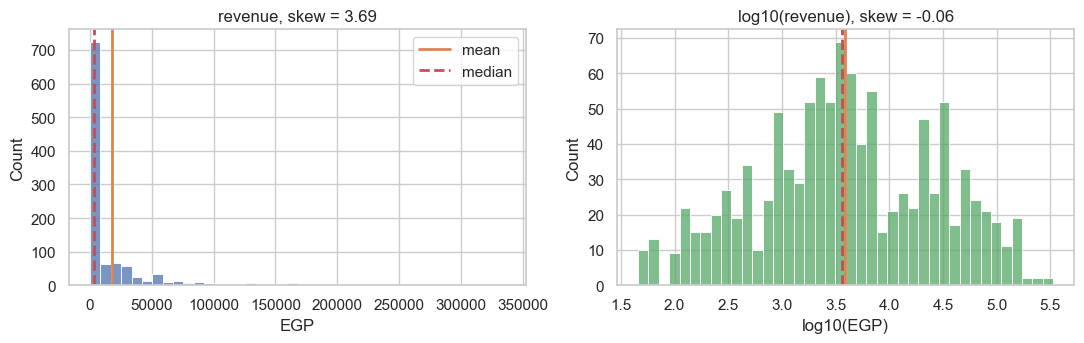

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
sns.histplot(rev, bins=40, ax=axes[0])
axes[0].set(title=f"revenue, skew = {rev.skew():.2f}", xlabel="EGP")
sns.histplot(np.log10(rev), bins=40, ax=axes[1], color="C2")
axes[1].set(title=f"log10(revenue), skew = {np.log10(rev).skew():.2f}", xlabel="log10(EGP)")
for ax, x in [(axes[0], rev), (axes[1], np.log10(rev))]:
    ax.axvline(x.mean(), color="C1", lw=2, label="mean")
    ax.axvline(x.median(), color="C3", lw=2, ls="--", label="median")
axes[0].legend()
plt.tight_layout()
plt.show()

Revenue's skew is 3.7: very strong. On a log scale it's almost 0, and the mean and median line up.

**Skew tells you which numbers to report:**

| Shape | Center | Spread |
|---|---|---|
| roughly symmetric (−1 to 1) | mean | std |
| strongly skewed | median | IQR |

---
# 6️⃣ Groups: one number per group

## 6.1 `groupby` + `agg`

In [22]:
g = done.groupby("category")["revenue"].agg(["count", "mean", "median", "std", "sum"])
g.sort_values("median", ascending=False)

,count,mean,median,std,sum
category,,,,,
Electronics,269,"58,540.72","41,800.00","52,090.66","15,747,455.00"
Furniture,184,"12,286.13","6,982.50","12,570.28","2,260,647.05"
Accessories,453,"3,011.77","2,360.00","2,228.76","1,364,333.45"
Stationery,168,237.42,221.70,144.48,"39,886.50"


Inside each category the gap between the mean and the median is much smaller than in the whole column.
A lot of the skew in revenue came from **mixing** groups: pens and laptops in one column.

## 6.2 ⚠️ The mean of the means is not the mean

In [23]:
print(f"mean of the 4 category means: {g['mean'].mean():,.0f}")
print(f"mean of all order lines:      {rev.mean():,.0f}")
print(f"weighted by count:            {(g['mean'] * g['count']).sum() / g['count'].sum():,.0f}")

mean of the 4 category means: 18,519
mean of all order lines:      18,075
weighted by count:            18,075


Averaging the four category means gives each category the same weight, whether it has 453 lines or 168.
The overall mean weights each **line** equally. Weight the group means by their counts and you get it back.

## 6.3 Always say how many

A median of a group of 3 means much less than a median of 400. Keep `count` next to every group statistic.

---
# 🧰 Summary

| Question | Symmetric data | Skewed data / outliers | Code |
|---|---|---|---|
| Typical value | mean | median (or trimmed mean) | `mean()`, `median()`, `stats.trim_mean` |
| Most common | mode | mode | `mode()`, `value_counts()` |
| Spread | std | IQR | `std()`, `quantile([.25, .75])` |
| Whole picture | five-number summary | | `describe()` |
| Unusual values | z-score > 3 | IQR rule, within groups or on log | |
| Lopsided? | skew near 0 | skew beyond ±1 | `skew()` |

* Pandas `std()` divides by `n - 1`, NumPy `np.std` by `n`.
* An outlier is a question, not an error.
* The mean of group means is not the overall mean. Keep the `count`.

**Next part of the course:** NumPy: arrays, and computing on a whole column at once.

📚 All the lessons of the course: [zero-grad.com/courses/da](https://zero-grad.com/courses/da/)